# E-Commerce Customer Segmentation Using RFM

**Goal:** segment customers with K-Means and DBSCAN, visualize the groups with PCA and t-SNE, and turn the K-Means profiles into marketing personas.

Each row is one customer. The dataset includes raw RFM measures and precomputed scores/categories. This notebook uses only the raw measures for clustering so the models can form their own segments.

## Quick Result from This Dataset

- The file has 50,000 customers and 53 columns. All customer IDs are unique, and the three raw RFM features have no missing or negative values.
- K-Means selected **k = 2** by the sampled silhouette score. One group has 11,257 customers with lower average frequency and spend (25.5 purchases; $7,729 total spend per customer); the other has 38,743 customers with higher averages (120.9 purchases; $62,626 spend). Average recency is similar, so the split is mainly frequency and monetary value.
- The two PCA components explain **92%** of feature variance. t-SNE shows the same K-Means labels on a 3,000-customer sample.
- With the notebook's starting DBSCAN eps, DBSCAN returns 6 clusters, but most customers fall into two large groups and a few small fragments. Its cluster count changes sharply as eps changes, so K-Means gives the clearer starting point for marketing personas on this dataset.

## 1. Import Libraries

In [1]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = str(os.cpu_count() or 1)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

## 2. Load Data

In [2]:
file_path = r'/Users/farhan/Downloads/E-commerce_Customer_Segmentation_2026.csv'

df = pd.read_csv(file_path)
df.head()

,customer_id,customer_segment,segment_category,age,age_group,gender,country,city,income_bracket,education_level,employment_type,marital_status,tenure_months,total_purchases,avg_order_value_usd,total_spent_usd,purchase_frequency,days_since_last_purchase,preferred_category_1,preferred_category_2,preferred_category_3,shopping_channel,device_used,payment_method,return_count,complaint_count,satisfaction_score,satisfaction_level,loyalty_tier,email_open_rate,click_through_rate,conversion_rate,social_media_presence,customer_lifetime_value_usd,customer_acquisition_cost_usd,customer_profitability_usd,recency_score,frequency_score,monetary_score,rfm_score,churn_risk_score,customer_health_score,dataset_year,customer_value_category,activity_status,health_status,churn_risk_category,rfm_category,profitability_category,engagement_level,behavior_segment,device_preference,clv_category
0,CUST-000001,Consumer,High Value Inactive,70,65+,Male,Canada,Winnipeg,150K+,Professional,Unemployed,Widowed,77,28,912.60,25552.80,Quarterly,63,Sports & Fitness,Home & Kitchen,NaN,In-Store,Tablet,Debit Card,15,13,5,Very Satisfied,Platinum,0.018,0.067,0.022,NaN,21281.07,96.74,21184.33,3,3,4,10,39,100,2026,High,Dormant,Excellent,Low,Potential Loyalists,High Profit,Low,Regular Buyer,Multi-Device,High CLV
1,CUST-000002,Premium,High Value Inactive,53,45-54,Female,Germany,Essen,25K-50K,High School,Student,Divorced,80,75,300.86,22564.50,Rarely,342,Automotive,Beauty,Fashion,Marketplace,Desktop,Bank Transfer,1,14,5,Very Satisfied,Gold,0.084,0.085,0.293,NaN,28347.21,199.28,28147.93,1,4,3,8,42,100,2026,Medium,Inactive,Excellent,Medium,At Risk,High Profit,Low,Occasional Buyer,Desktop-First,High CLV
2,CUST-000003,Consumer,High Value Inactive,82,65+,Male,Mexico,Puebla,75K-100K,Bachelors,Student,Married,86,163,663.91,108217.33,Quarterly,64,Fashion,Automotive,Beauty,In-Store,Tablet,Bank Transfer,1,4,3,Neutral,Diamond,0.279,0.428,0.222,NaN,103909.84,112.39,103797.45,3,5,5,13,0,100,2026,Very High,Dormant,Excellent,Very Low,Champions,High Profit,Low,Regular Buyer,Multi-Device,High CLV
3,CUST-000004,Enterprise,High Value Active,18,18-24,Male,Singapore,Singapore,150K+,Masters,Retired,Divorced,26,192,613.60,117811.20,Weekly,2,Electronics,Toys,NaN,Online,Mobile,Credit Card,11,8,5,Very Satisfied,Diamond,0.899,0.282,0.142,"Twitter, YouTube, TikTok",171318.41,140.71,171177.70,5,5,5,15,14,100,2026,Very High,Active,Excellent,Very Low,Champions,High Profit,High,Frequent Buyer,Mobile-First,High CLV
4,CUST-000005,Premium,High Value Active,64,55-64,Male,United Arab Emirates,Fujairah,150K+,PhD,Retired,Divorced,90,31,651.65,20201.15,Weekly,4,Home & Kitchen,Office Supplies,Grocery,Online,Desktop,Credit Card,7,11,1,Very Dissatisfied,Gold,0.835,0.094,0.180,"TikTok, YouTube",24465.47,52.82,24412.65,5,3,3,11,45,60,2026,Medium,Active,Fair,Medium,Loyal,High Profit,Medium,Occasional Buyer,Desktop-First,High CLV


## 3. Check the Data

In [3]:
print('Rows and columns:', df.shape)
print('Duplicate rows:', df.duplicated().sum())
print('Unique customer IDs:', df['customer_id'].nunique())
print('Dataset year:', df['dataset_year'].unique())

Rows and columns: (50000, 53)
Duplicate rows: 0
Unique customer IDs: 50000
Dataset year: [2026]


In [4]:
df[['days_since_last_purchase', 'total_purchases', 'total_spent_usd']].describe().round(2)

,days_since_last_purchase,total_purchases,total_spent_usd
count,50000.00,50000.00,50000.00
mean,62.97,99.42,50266.55
std,93.28,57.78,44071.21
min,0.00,0.00,0.00
25%,2.00,49.00,13893.58
50%,19.00,99.00,37541.62
75%,77.00,150.00,76811.24
max,365.00,199.00,198574.14


In [5]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0].sort_values(ascending=False)

preferred_category_3     33257
preferred_category_2     16743
social_media_presence    12420
loyalty_tier              1272
dtype: int64

## 4. Select RFM Features

Recency is the number of days since the last purchase; a lower value means a more recent customer. Frequency is the number of purchases, and Monetary is total spend.

In [6]:
rfm_data = df[['customer_id',
                 'days_since_last_purchase',
                 'total_purchases',
                 'total_spent_usd']].copy()

rfm_data.columns = ['customer_id', 'Recency', 'Frequency', 'Monetary']

rfm_features = ['Recency', 'Frequency', 'Monetary']

print('Missing RFM values:', rfm_data[rfm_features].isnull().sum().sum())
print('Rows with a negative RFM value:', (rfm_data[rfm_features] < 0).any(axis=1).sum())
rfm_data.head()

Missing RFM values: 0
Rows with a negative RFM value: 0


,customer_id,Recency,Frequency,Monetary
0,CUST-000001,63,28,25552.80
1,CUST-000002,342,75,22564.50
2,CUST-000003,64,163,108217.33
3,CUST-000004,2,192,117811.20
4,CUST-000005,4,31,20201.15


## 5. Explore RFM Distributions

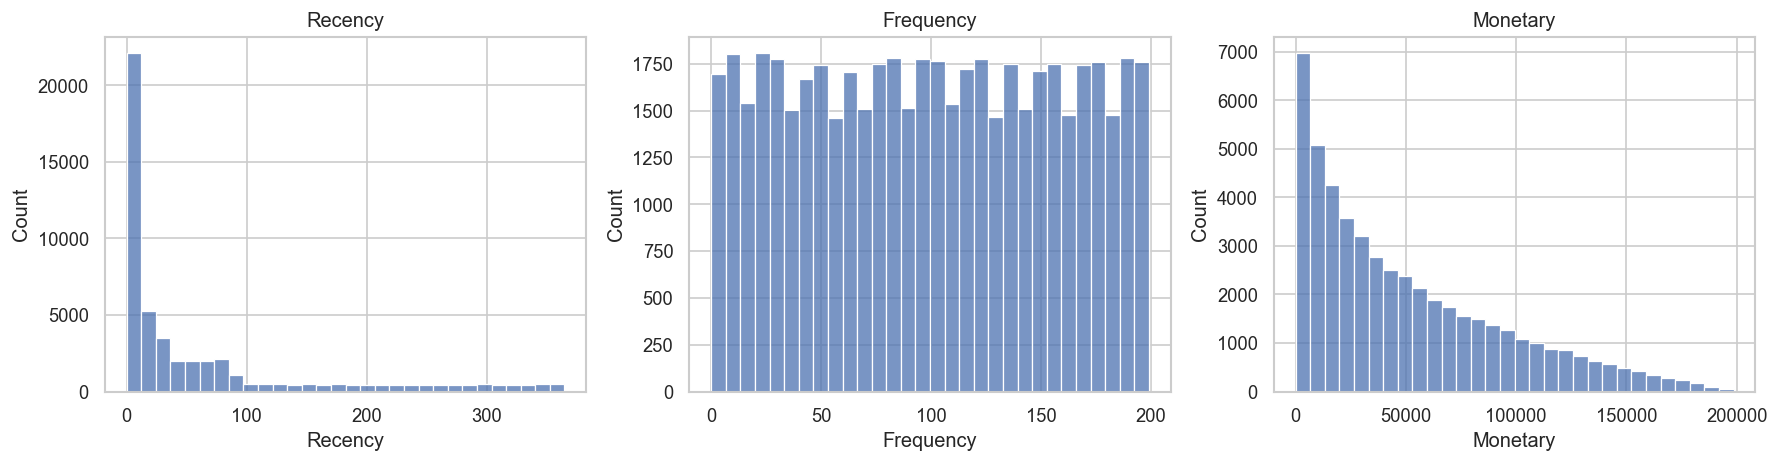

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for column, axis in zip(rfm_features, axes):
    sns.histplot(data=rfm_data, x=column, bins=30, ax=axis)
    axis.set_title(column)

plt.tight_layout()
plt.show()

## 6. Transform and Scale RFM

The three measures have different ranges and right-skew. log1p reduces skew, then StandardScaler puts the features on comparable scales.

In [8]:
rfm_log = np.log1p(rfm_data[rfm_features])

scalar = StandardScaler()
X_scaled = scalar.fit_transform(rfm_log)

print('Scaled data shape:', X_scaled.shape)

Scaled data shape: (50000, 3)


## 7. Find a K-Means Cluster Count

In [9]:
sample_size = min(10000, len(X_scaled))
sample_indices = np.random.RandomState(42).choice(len(X_scaled),
                                                  size=sample_size,
                                                  replace=False)
X_sample = X_scaled[sample_indices]

inertia = []
silhouette_values = []
silhouette_k_values = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_label = kmeans.fit_predict(X_sample)
    inertia.append(kmeans.inertia_)

    if k > 1:
        silhouette_values.append(
            silhouette_score(X_sample,
                             cluster_label,
                             sample_size=min(3000, sample_size),
                             random_state=42,
                             n_jobs=1)
        )
        silhouette_k_values.append(k)

best_k = silhouette_k_values[np.argmax(silhouette_values)]
print('K with the highest sampled silhouette score:', best_k)

K with the highest sampled silhouette score: 2


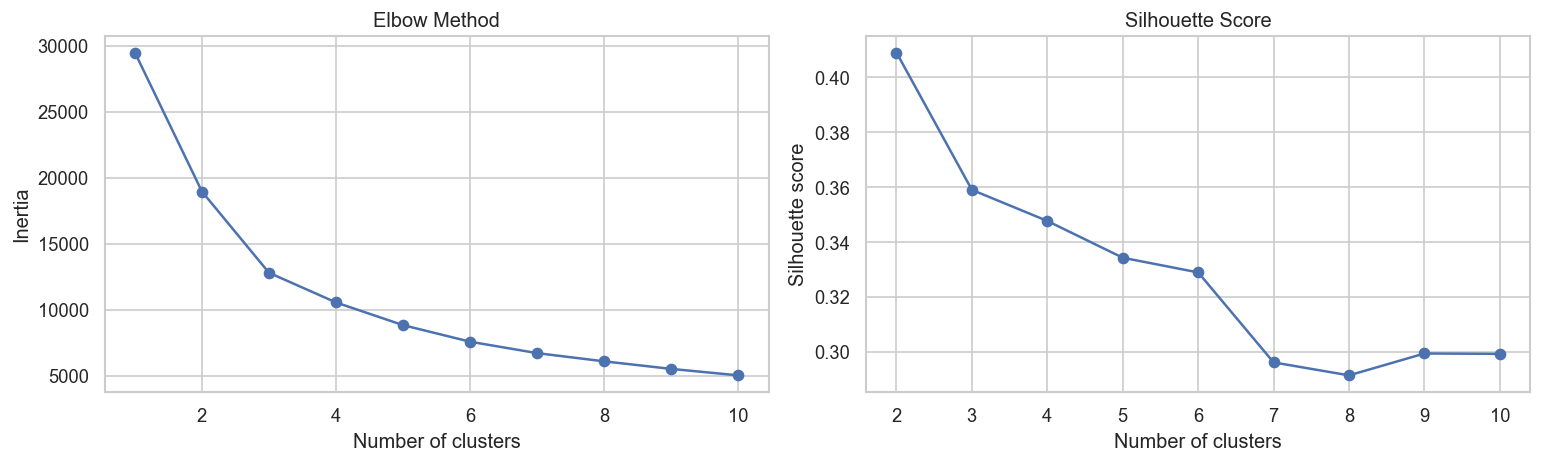

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(list(K_range), inertia, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of clusters')
axes[0].set_ylabel('Inertia')

axes[1].plot(silhouette_k_values, silhouette_values, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters')
axes[1].set_ylabel('Silhouette score')

plt.tight_layout()
plt.show()

The elbow plot shows how quickly within-cluster variation falls as k increases. The silhouette score is a second guide; use both plots and whether the resulting groups are easy to explain when making the final choice.

## 8. Fit the Final K-Means Model

In [11]:
K_means_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_label = K_means_final.fit_predict(X_scaled)

rfm_data['KMeans_cluster'] = kmeans_label
df_kmeans = df.loc[rfm_data.index].copy()
df_kmeans['KMeans_cluster'] = kmeans_label

print('K-Means cluster sizes:')
print(df_kmeans['KMeans_cluster'].value_counts().sort_index())

K-Means cluster sizes:
KMeans_cluster
0    11257
1    38743
Name: count, dtype: int64


In [12]:
kmeans_profile = rfm_data.groupby('KMeans_cluster').agg(
    Customer_Count=('customer_id', 'count'),
    Recency_Mean=('Recency', 'mean'),
    Frequency_Mean=('Frequency', 'mean'),
    Monetary_Mean=('Monetary', 'mean')
).round(2)
kmeans_profile['Customer_Pct'] = (kmeans_profile['Customer_Count'] / len(rfm_data) * 100).round(2)

kmeans_profile

,Customer_Count,Recency_Mean,Frequency_Mean,Monetary_Mean,Customer_Pct
KMeans_cluster,,,,,
0,11257,62.68,25.46,7729.26,22.51
1,38743,63.05,120.91,62626.00,77.49


## 9. Visualize K-Means with PCA

In [13]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['KMeans_cluster'] = kmeans_label

print('Variance explained by two components:',
      round(pca.explained_variance_ratio_.sum(), 3))

Variance explained by two components: 0.92


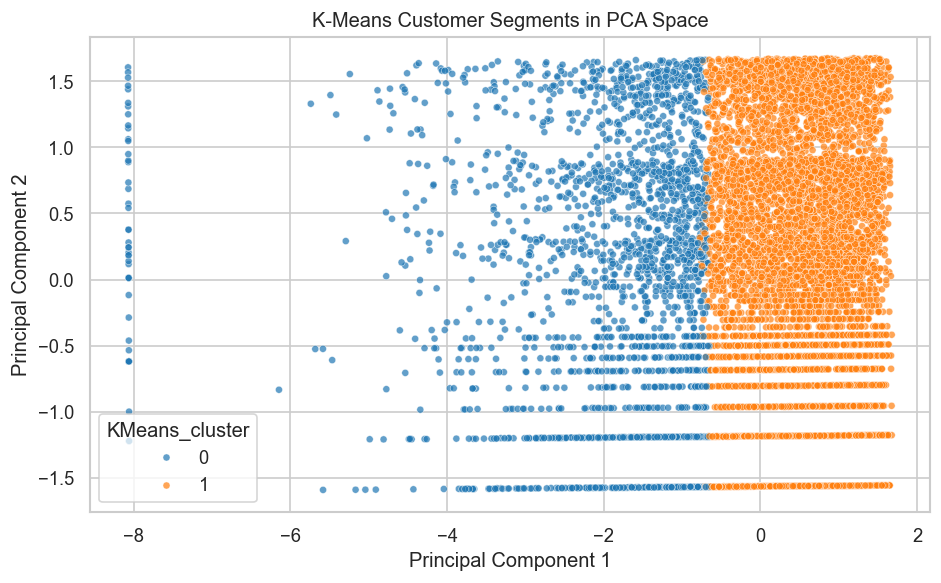

In [14]:
pca_sample = df_pca.sample(n=min(10000, len(df_pca)), random_state=42)

sns.scatterplot(data=pca_sample,
                x='PC1',
                y='PC2',
                hue='KMeans_cluster',
                palette='tab10',
                s=18,
                alpha=0.7)

plt.title('K-Means Customer Segments in PCA Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.tight_layout()
plt.show()

## 10. Visualize K-Means with t-SNE

In [15]:
tsne_sample_size = min(3000, len(X_scaled))
tsne_indices = np.random.RandomState(42).choice(len(X_scaled),
                                                size=tsne_sample_size,
                                                replace=False)

X_tsne = TSNE(n_components=2,
              random_state=42,
              perplexity=30,
              init='pca',
              learning_rate='auto').fit_transform(X_scaled[tsne_indices])

df_tsne = pd.DataFrame(X_tsne, columns=['tSNE_1', 'tSNE_2'])
df_tsne['KMeans_cluster'] = kmeans_label[tsne_indices]

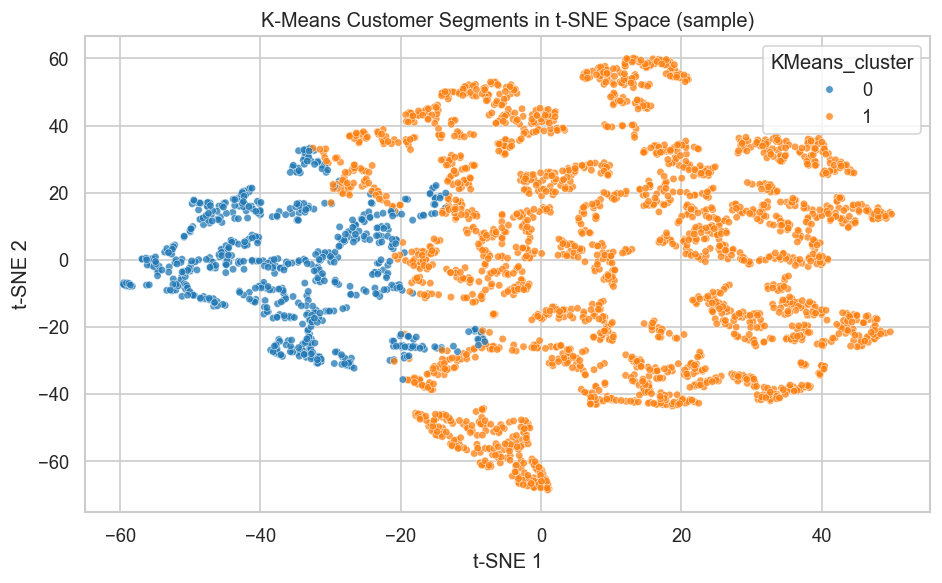

In [16]:
sns.scatterplot(data=df_tsne,
                x='tSNE_1',
                y='tSNE_2',
                hue='KMeans_cluster',
                palette='tab10',
                s=20,
                alpha=0.75)

plt.title('K-Means Customer Segments in t-SNE Space (sample)')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.tight_layout()
plt.show()

t-SNE is used here to display a 3D feature space in two dimensions. It is a visualization only: distances between far-apart islands and the displayed cluster shapes should not be treated as exact measurements.

## 11. Run DBSCAN

In [17]:
min_samples = 5
neighbours = NearestNeighbors(n_neighbors=min_samples, n_jobs=1)
neighbours_fit = neighbours.fit(X_scaled)
distances, indices = neighbours_fit.kneighbors(X_scaled)

k_distances = np.sort(distances[:, -1])
print('90th percentile of the 5-neighbour distances:',
      round(np.percentile(k_distances, 90), 3))
print('99.75th percentile of the 5-neighbour distances:',
      round(np.percentile(k_distances, 99.75), 3))

90th percentile of the 5-neighbour distances: 0.115
99.75th percentile of the 5-neighbour distances: 0.341


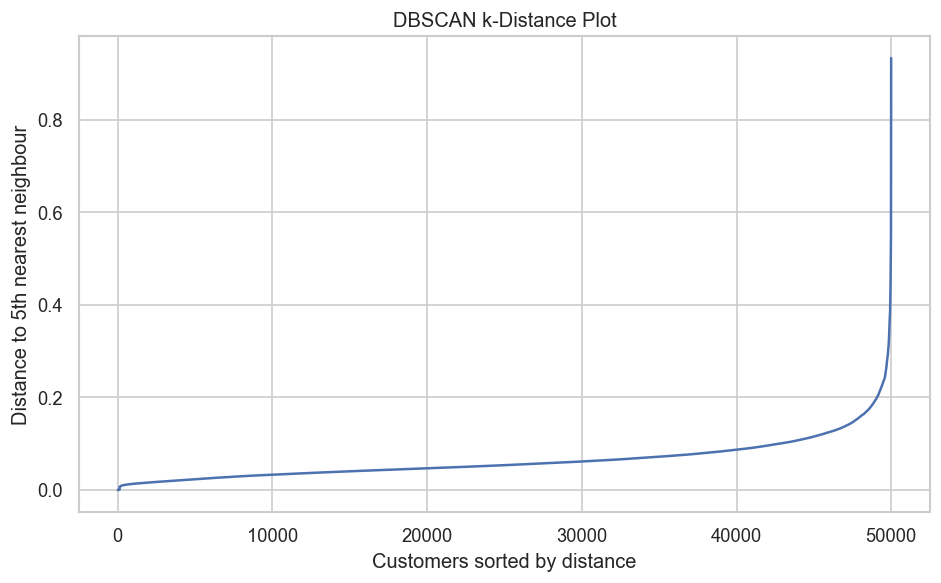

In [18]:
plt.plot(k_distances)
plt.title('DBSCAN k-Distance Plot')
plt.xlabel('Customers sorted by distance')
plt.ylabel('Distance to 5th nearest neighbour')
plt.tight_layout()
plt.show()

The k-distance curve helps choose DBSCAN's eps. The percentile below is a starting value for this dataset, not a universal rule. Compare nearby values and check whether the number and size of clusters make sense.

In [19]:
eps_percentile = 99.75
eps_value = np.percentile(k_distances, eps_percentile)

eps_percentiles = [90, 95, 98, 99, 99.75, 99.9]
dbscan_results = []

for percentile in eps_percentiles:
    eps_check = np.percentile(k_distances, percentile)
    labels_check = DBSCAN(eps=eps_check,
                          min_samples=min_samples,
                          n_jobs=1).fit_predict(X_scaled)
    cluster_count = len(set(labels_check) - {-1})
    noise_percent = (labels_check == -1).mean() * 100

    dbscan_results.append([percentile,
                           round(eps_check, 3),
                           cluster_count,
                           round(noise_percent, 2)])

dbscan_sensitivity = pd.DataFrame(dbscan_results,
                                  columns=['Distance percentile',
                                           'eps',
                                           'Number of clusters',
                                           'Noise customers (%)'])

dbscan_sensitivity

,Distance percentile,eps,Number of clusters,Noise customers (%)
0,90.00,0.115,230,6.43
1,95.00,0.146,118,3.01
2,98.00,0.195,48,1.13
3,99.00,0.235,15,0.56
4,99.75,0.341,6,0.13
5,99.90,0.422,3,0.04


In [20]:
dbscan = DBSCAN(eps=eps_value, min_samples=min_samples, n_jobs=1)
dbscan_label = dbscan.fit_predict(X_scaled)
rfm_data['DBSCAN_cluster'] = dbscan_label
df_kmeans['DBSCAN_cluster'] = dbscan_label

dbscan_cluster_count = len(set(dbscan_label) - {-1})
dbscan_noise_percent = (dbscan_label == -1).mean() * 100

print('eps value:', round(eps_value, 3))
print('DBSCAN clusters (noise excluded):', dbscan_cluster_count)
print('Noise customers (%):', round(dbscan_noise_percent, 2))
print('DBSCAN label counts:')
print(pd.Series(dbscan_label).value_counts().sort_index())

eps value: 0.341
DBSCAN clusters (noise excluded): 6
Noise customers (%): 0.13
DBSCAN label counts:
-1       65
 0    44427
 1     5029
 2      199
 3      243
 4       19
 5       18
Name: count, dtype: int64


In [21]:
assigned_customers = dbscan_label != -1

if len(set(dbscan_label[assigned_customers])) > 1:
    dbscan_silhouette = silhouette_score(
        X_scaled[assigned_customers],
        dbscan_label[assigned_customers],
        sample_size=min(3000, assigned_customers.sum()),
        random_state=42,
        n_jobs=1
    )
    print('DBSCAN silhouette on non-noise customers:',
          round(dbscan_silhouette, 3))
else:
    print('DBSCAN silhouette was skipped because fewer than two non-noise clusters were found.')

DBSCAN silhouette on non-noise customers: 0.173


## 12. Visualize DBSCAN with PCA

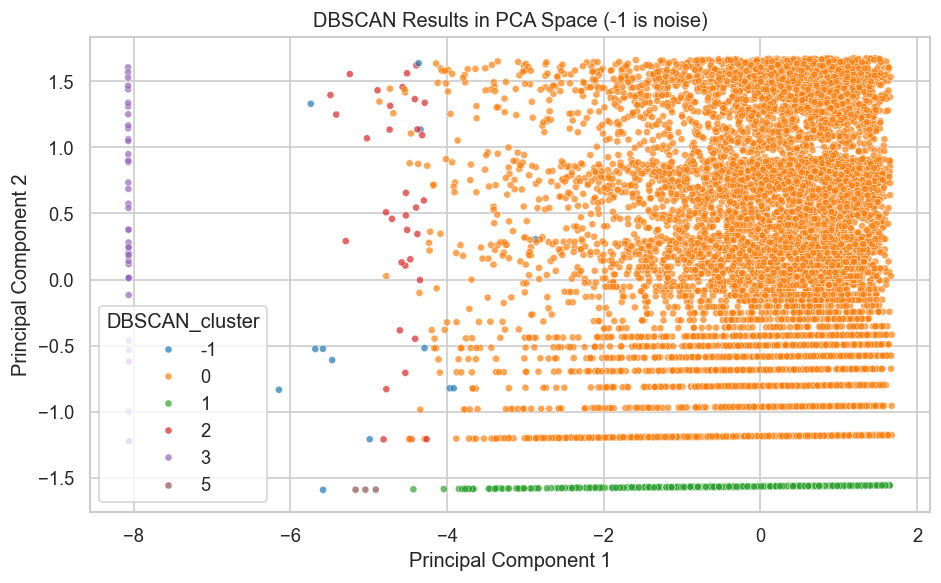

In [22]:
df_pca['DBSCAN_cluster'] = dbscan_label
pca_dbscan_sample = df_pca.sample(n=min(10000, len(df_pca)), random_state=42)

sns.scatterplot(data=pca_dbscan_sample,
                x='PC1',
                y='PC2',
                hue='DBSCAN_cluster',
                palette='tab10',
                s=18,
                alpha=0.7)

plt.title('DBSCAN Results in PCA Space (-1 is noise)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.tight_layout()
plt.show()

DBSCAN can label points as noise (-1). A very large cluster with many tiny clusters, or a result that changes sharply across nearby eps values, suggests the data may not have clear density-separated groups in this feature space.

## 13. Create Marketing Personas from K-Means

In [23]:
def most_common_value(series):
    values = series.mode()
    if len(values) == 0:
        return 'Not available'
    return values.iloc[0]


persona_table = df_kmeans.groupby('KMeans_cluster').agg(
    Customer_Count=('customer_id', 'count'),
    Recency_Median=('days_since_last_purchase', 'median'),
    Frequency_Median=('total_purchases', 'median'),
    Monetary_Median=('total_spent_usd', 'median'),
    Satisfaction_Mean=('satisfaction_score', 'mean'),
    Top_Category=('preferred_category_1', most_common_value),
    Main_Channel=('shopping_channel', most_common_value),
    Loyalty_Tier=('loyalty_tier', most_common_value)
).reset_index()

recency_cut = persona_table['Recency_Median'].median()
frequency_cut = persona_table['Frequency_Median'].median()
monetary_cut = persona_table['Monetary_Median'].median()


def assign_persona(row):
    if (row['Recency_Median'] <= recency_cut
            and row['Frequency_Median'] >= frequency_cut
            and row['Monetary_Median'] >= monetary_cut):
        return 'Champions'
    elif (row['Recency_Median'] > recency_cut
            and row['Frequency_Median'] >= frequency_cut):
        return 'At-Risk Loyal Customers'
    elif (row['Monetary_Median'] >= monetary_cut
            and row['Frequency_Median'] < frequency_cut):
        return 'High-Value Occasional Customers'
    elif row['Recency_Median'] <= recency_cut:
        return 'Active Emerging Customers'
    else:
        return 'Reactivation Candidates'


persona_table['Persona'] = persona_table.apply(assign_persona, axis=1)
persona_table['Suggested_Action'] = persona_table['Persona'].map({
    'Champions': 'Reward loyalty; offer VIP access and referral incentives.',
    'At-Risk Loyal Customers': 'Use a personalized win-back offer and remind them of loyalty benefits.',
    'High-Value Occasional Customers': 'Recommend premium or complementary products to encourage a repeat visit.',
    'Active Emerging Customers': 'Use discovery content and a low-friction second-purchase incentive.',
    'Reactivation Candidates': 'Try a low-cost reactivation message and limit repeated discounts if they do not respond.'
})

persona_table = persona_table.sort_values('KMeans_cluster')
persona_table.round(2)

,KMeans_cluster,Customer_Count,Recency_Median,Frequency_Median,Monetary_Median,Satisfaction_Mean,Top_Category,Main_Channel,Loyalty_Tier,Persona,Suggested_Action
0,0,11257,19.0,22.0,6034.77,3.00,Health & Personal Care,In-Store,Bronze,Active Emerging Customers,Use discovery content and a low-friction secon...
1,1,38743,19.0,122.0,52576.26,3.01,Home & Kitchen,Mobile App,Diamond,Champions,Reward loyalty; offer VIP access and referral ...


## 14. Case Study Summary

In [24]:
print('Customers clustered:', len(rfm_data))
print('K-Means clusters:', best_k)
print('DBSCAN clusters:', dbscan_cluster_count)
print('DBSCAN noise customers (%):', round(dbscan_noise_percent, 2))
print('PCA variance explained by 2 components:',
      round(pca.explained_variance_ratio_.sum(), 3))

print()
print('K-Means profiles and suggested marketing actions:')
persona_table[['KMeans_cluster',
               'Persona',
               'Customer_Count',
               'Recency_Median',
               'Frequency_Median',
               'Monetary_Median',
               'Top_Category',
               'Main_Channel',
               'Suggested_Action']].round(2)

Customers clustered: 50000
K-Means clusters: 2
DBSCAN clusters: 6
DBSCAN noise customers (%): 0.13
PCA variance explained by 2 components: 0.92

K-Means profiles and suggested marketing actions:


,KMeans_cluster,Persona,Customer_Count,Recency_Median,Frequency_Median,Monetary_Median,Top_Category,Main_Channel,Suggested_Action
0,0,Active Emerging Customers,11257,19.0,22.0,6034.77,Health & Personal Care,In-Store,Use discovery content and a low-friction secon...
1,1,Champions,38743,19.0,122.0,52576.26,Home & Kitchen,Mobile App,Reward loyalty; offer VIP access and referral ...


### Interpretation Notes

- The K-Means personas are assigned relative to the median cluster profiles in this dataset; the cluster numbers themselves have no business meaning.
- Use the persona table and plots to describe the groups in your own words. Treat each suggested action as a starting point for a marketing hypothesis, not proof that a campaign will work.
- Compare K-Means and DBSCAN using the cluster counts, noise share, sensitivity table, and plots. If DBSCAN produces many small clusters or changes sharply with eps, explain that density-based separation may not fit this dataset well.
- RFM clustering is unsupervised. Do not evaluate it with classification accuracy or use the dataset's precomputed segment labels as model inputs.